Challenge 3

Andrea Paola Gómez Jaime

Part A

In [4]:
import sklearn
import matplotlib.pyplot as plt
import numpy as np
from nilearn import datasets
from nilearn.maskers import NiftiLabelsMasker
from nilearn.image import index_img
import nibabel as nib
from nilearn import plotting

def get_features(labels_img):
    masker = NiftiLabelsMasker(labels_img=labels_img, standardize=True)
    return masker.fit_transform(brain_data.gray_matter_maps)

def split(X, y, n_train=80):
    return X[:n_train], X[n_train:], y[:n_train], y[n_train:]

In [5]:
#Snippet from TA Jack Plant
# get data

brain_data = datasets.fetch_oasis_vbm(n_subjects=100)
brain_data = datasets.fetch_oasis_vbm(
    n_subjects=100,
    data_dir=r"~\nilearn_data"
)


# WORKAROUND for datasets.fetch_atlas_craddock_2012()
# Replace the fetch command with a dictionary pointing to your downloaded file:
# (Make sure to update the path below to match where you saved it on your machine)
crad = {'scorr_mean': 'craddock_2011_parcellations/scorr05_mean_all.nii.gz'}

atlas_nii = index_img(crad['scorr_mean'], 11) # Note: this parameter needs to be modified for some tasks
masker = NiftiLabelsMasker(labels_img=atlas_nii, standardize=True)
input_variables = masker.fit_transform(brain_data.gray_matter_maps)
output_variable = np.array(brain_data.ext_vars.mf == 'F', dtype=int) # gives 1 for females and 0 for males

[fetch_oasis_vbm] Dataset directory found: C:\Users\Asus\nilearn_data\oasis1
[fetch_oasis_vbm] Dataset directory found: ~\nilearn_data\oasis1


C:\Users\Asus\AppData\Local\Temp\ipykernel_31240\613113794.py:18: FutureWarning: boolean values for 'standardize' will be deprecated in nilearn 0.15.0.
Use 'zscore_sample' instead of 'True' or use 'None' instead of 'False'.
  input_variables = masker.fit_transform(brain_data.gray_matter_maps)


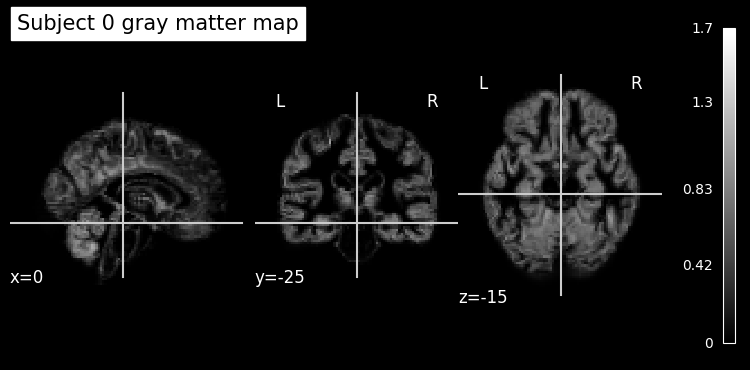

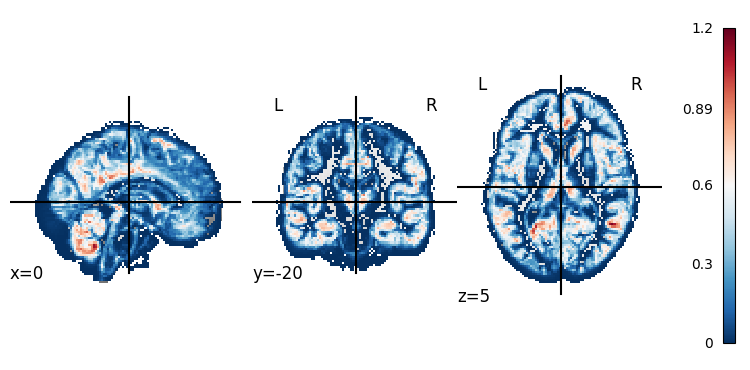

c:\Users\Asus\PyCharmMiscProject\.venv\Lib\site-packages\numpy\_core\fromnumeric.py:868: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  a.partition(kth, axis=axis, kind=kind, order=order)


id       OAS1_0001_MR1
mf                   F
hand                 R
age                 74
educ               2.0
ses                3.0
mmse              29.0
cdr                0.0
etiv              1344
nwbv             0.743
asf              1.306
delay              NaN
Name: 0, dtype: object


In [6]:
from nilearn import plotting

plotting.plot_anat(brain_data.gray_matter_maps[0], title="Subject 0 gray matter map")
plotting.show()
plotting.plot_stat_map(brain_data.gray_matter_maps[0])
plotting.show()
plotting.view_img(brain_data.gray_matter_maps[0])
plotting.show()

print(brain_data.ext_vars.iloc[0])


Exercise 1

In [7]:
import sklearn
res = np.arange(100, 1001, 100)

def run_atlas_sweep(atlas_items, get_labels_img, y=output_variable):
    accuracies = []
    for item in atlas_items:
        X = get_features(get_labels_img(item))
        X_train, X_test, y_train, y_test = split(X, y)
        logreg = sklearn.linear_model.LogisticRegression(C=1.0)
        accuracies.append(logreg.fit(X_train, y_train).score(X_test, y_test))
    return accuracies

accuracies = run_atlas_sweep(res, lambda r: datasets.fetch_atlas_schaefer_2018(n_rois=r).maps)

print(len(accuracies))
print(res.shape)

[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018


C:\Users\Asus\AppData\Local\Temp\ipykernel_31240\3507887655.py:12: FutureWarning: boolean values for 'standardize' will be deprecated in nilearn 0.15.0.
Use 'zscore_sample' instead of 'True' or use 'None' instead of 'False'.
  return masker.fit_transform(brain_data.gray_matter_maps)


[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018


C:\Users\Asus\AppData\Local\Temp\ipykernel_31240\3507887655.py:12: FutureWarning: boolean values for 'standardize' will be deprecated in nilearn 0.15.0.
Use 'zscore_sample' instead of 'True' or use 'None' instead of 'False'.
  return masker.fit_transform(brain_data.gray_matter_maps)


[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018


...

[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018


C:\Users\Asus\AppData\Local\Temp\ipykernel_31240\3507887655.py:12: FutureWarning: boolean values for 'standardize' will be deprecated in nilearn 0.15.0.
Use 'zscore_sample' instead of 'True' or use 'None' instead of 'False'.
  return masker.fit_transform(brain_data.gray_matter_maps)


[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018


C:\Users\Asus\AppData\Local\Temp\ipykernel_31240\3507887655.py:12: FutureWarning: boolean values for 'standardize' will be deprecated in nilearn 0.15.0.
Use 'zscore_sample' instead of 'True' or use 'None' instead of 'False'.
  return masker.fit_transform(brain_data.gray_matter_maps)


10
(10,)


In [8]:
for n_rois, acc in zip(res, accuracies):
    print(f"n_rois={n_rois}: {acc*100:.2f}%")


n_rois=100: 55.00%
n_rois=200: 70.00%
n_rois=300: 75.00%
n_rois=400: 80.00%
n_rois=500: 75.00%
n_rois=600: 70.00%
n_rois=700: 70.00%
n_rois=800: 80.00%
n_rois=900: 80.00%
n_rois=1000: 75.00%


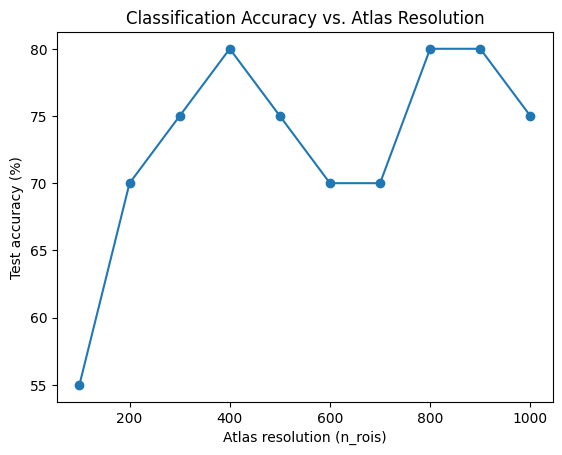

In [9]:
plt.plot(res, [a*100 for a in accuracies], marker='o')
plt.xlabel("Atlas resolution (n_rois)")
plt.ylabel("Test accuracy (%)")
plt.title("Classification Accuracy vs. Atlas Resolution")
plt.show()


Exercise 2

In [10]:
atlas_1000 = datasets.fetch_atlas_schaefer_2018(n_rois=1000)
X = get_features(atlas_1000.maps)
n_components_list = range(1, 26)

def run_pca_sweep(X, y, n_components_list):
    X_train, X_test, y_train, y_test = split(X, y)
    accuracies = []
    for k in n_components_list:
        pca = sklearn.decomposition.PCA(n_components=k)
        X_train_pca = pca.fit_transform(X_train)
        X_test_pca = pca.transform(X_test)
        logreg = sklearn.linear_model.LogisticRegression(C=1.0)
        accuracies.append(logreg.fit(X_train_pca, y_train).score(X_test_pca, y_test))
    return accuracies

accuracies = run_pca_sweep(X, output_variable, n_components_list)

[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018


C:\Users\Asus\AppData\Local\Temp\ipykernel_31240\3507887655.py:12: FutureWarning: boolean values for 'standardize' will be deprecated in nilearn 0.15.0.
Use 'zscore_sample' instead of 'True' or use 'None' instead of 'False'.
  return masker.fit_transform(brain_data.gray_matter_maps)


In [11]:
for n_rois, acc in zip(n_components_list, accuracies):
    print(f"n_rois={n_rois}: {acc*100:.2f}%")

n_rois=1: 60.00%
n_rois=2: 60.00%
n_rois=3: 60.00%
n_rois=4: 60.00%
n_rois=5: 60.00%
n_rois=6: 60.00%
n_rois=7: 60.00%
n_rois=8: 65.00%
n_rois=9: 65.00%
n_rois=10: 60.00%
n_rois=11: 65.00%
n_rois=12: 65.00%
n_rois=13: 65.00%
n_rois=14: 55.00%
n_rois=15: 70.00%
n_rois=16: 65.00%
n_rois=17: 75.00%
n_rois=18: 75.00%
n_rois=19: 80.00%
n_rois=20: 75.00%
n_rois=21: 70.00%
n_rois=22: 70.00%
n_rois=23: 70.00%
n_rois=24: 75.00%
n_rois=25: 90.00%


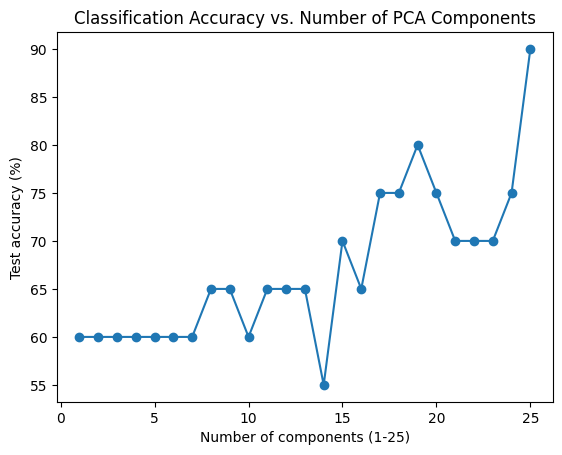

In [12]:
plt.plot(n_components_list, [a*100 for a in accuracies], marker='o')
plt.xlabel("Number of components (1-25)")
plt.ylabel("Test accuracy (%)")
plt.title("Classification Accuracy vs. Number of PCA Components")
plt.show()

Exercise 3

In [13]:
atlas_1000 = datasets.fetch_atlas_schaefer_2018(n_rois=1000)
X = get_features(atlas_1000.maps)
n_components_list = range(1, 26)

def run_kmeans_sweep(X, y, n_clusters_list):
    X_train, X_test, y_train, y_test = split(X, y)
    accuracies = []
    for k in n_clusters_list:
        kmeans = sklearn.cluster.KMeans(n_clusters=k, random_state=0)
        X_train_km = kmeans.fit_transform(X_train)
        X_test_km = kmeans.transform(X_test)
        logreg = sklearn.linear_model.LogisticRegression(C=1.0)
        accuracies.append(logreg.fit(X_train_km, y_train).score(X_test_km, y_test))
    return accuracies

accuracies = run_kmeans_sweep(X, output_variable, n_components_list)

[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018


C:\Users\Asus\AppData\Local\Temp\ipykernel_31240\3507887655.py:12: FutureWarning: boolean values for 'standardize' will be deprecated in nilearn 0.15.0.
Use 'zscore_sample' instead of 'True' or use 'None' instead of 'False'.
  return masker.fit_transform(brain_data.gray_matter_maps)
c:\Users\Asus\PyCharmMiscProject\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Users\Asus\PyCharmMiscProject\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning

In [14]:
for n_rois, acc in zip(n_components_list, accuracies):
    print(f"n_rois={n_rois}: {acc*100:.2f}%")

n_rois=1: 40.00%
n_rois=2: 55.00%
n_rois=3: 60.00%
n_rois=4: 55.00%
n_rois=5: 55.00%
n_rois=6: 55.00%
n_rois=7: 60.00%
n_rois=8: 60.00%
n_rois=9: 50.00%
n_rois=10: 55.00%
n_rois=11: 55.00%
n_rois=12: 55.00%
n_rois=13: 55.00%
n_rois=14: 70.00%
n_rois=15: 70.00%
n_rois=16: 85.00%
n_rois=17: 85.00%
n_rois=18: 85.00%
n_rois=19: 85.00%
n_rois=20: 90.00%
n_rois=21: 70.00%
n_rois=22: 70.00%
n_rois=23: 70.00%
n_rois=24: 80.00%
n_rois=25: 70.00%


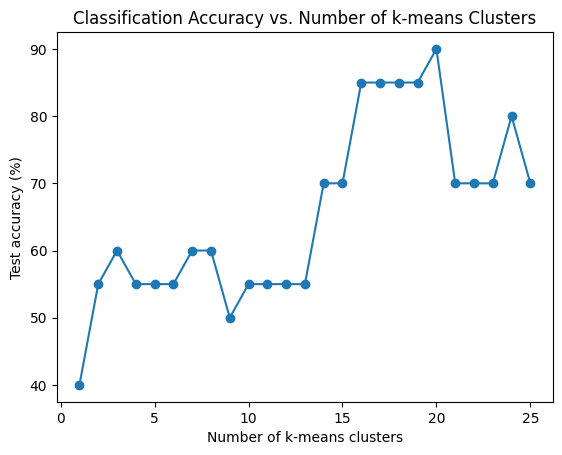

In [15]:
plt.plot(n_components_list, [a*100 for a in accuracies], marker='o')
plt.xlabel("Number of k-means clusters")
plt.ylabel("Test accuracy (%)")
plt.title("Classification Accuracy vs. Number of k-means Clusters")
plt.show()


Exercise 4

In [16]:
atlas_1000 = datasets.fetch_atlas_schaefer_2018(n_rois=1000)
X = get_features(atlas_1000.maps)
k_list = [2, 4, 6, 8, 10]

def run_selectk_sweep(X, y, k_list):
    X_train, X_test, y_train, y_test = split(X, y)
    accuracies = []
    for k in k_list:
        kb = sklearn.feature_selection.SelectKBest(score_func=sklearn.feature_selection.f_classif, k=k)
        X_train_kb = kb.fit_transform(X_train, y_train)
        X_test_kb = kb.transform(X_test)
        logreg = sklearn.linear_model.LogisticRegression(C=1.0)
        accuracies.append(logreg.fit(X_train_kb, y_train).score(X_test_kb, y_test))
    return accuracies

accuracies = run_selectk_sweep(X, output_variable, k_list)

[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018


C:\Users\Asus\AppData\Local\Temp\ipykernel_31240\3507887655.py:12: FutureWarning: boolean values for 'standardize' will be deprecated in nilearn 0.15.0.
Use 'zscore_sample' instead of 'True' or use 'None' instead of 'False'.
  return masker.fit_transform(brain_data.gray_matter_maps)


In [17]:
for k, acc in zip(k_list, accuracies):
    print(f"k={k}: {acc*100:.2f}%")

k=2: 80.00%
k=4: 80.00%
k=6: 80.00%
k=8: 80.00%
k=10: 75.00%


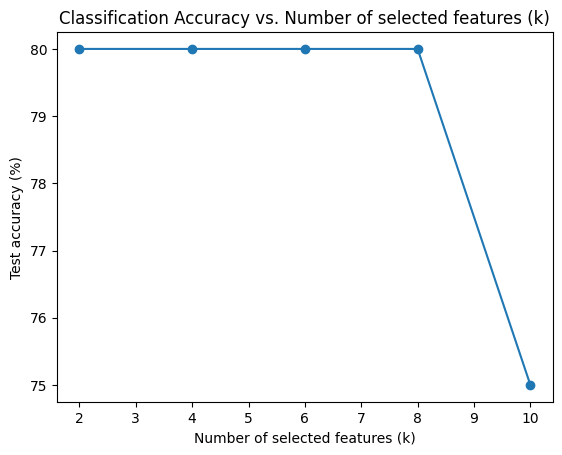

In [18]:
plt.plot(k_list, [a*100 for a in accuracies], marker='o')
plt.xlabel("Number of selected features (k)")
plt.ylabel("Test accuracy (%)")
plt.title("Classification Accuracy vs. Number of selected features (k)")
plt.show()

Exercise 5

In [19]:
resolutions = np.arange(100, 1001, 100)

def run_stacking_sweep(atlas_items, get_labels_img, y=output_variable):
    y_train, y_test = y[:80], y[80:]
    train_proba_list = []
    test_proba_list = []
    for item in atlas_items:
        X = get_features(get_labels_img(item))
        X_train, X_test = X[:80], X[80:]
        logreg = sklearn.linear_model.LogisticRegression(C=1.0)
        logreg.fit(X_train, y_train)
        train_proba_list.append(logreg.predict_proba(X_train)[:, 1])
        test_proba_list.append(logreg.predict_proba(X_test)[:, 1])

    meta_X_train = np.column_stack(train_proba_list)  #stack the 10 prob in meta-feature matrix
    meta_X_test = np.column_stack(test_proba_list)

    stack_model = sklearn.linear_model.LogisticRegression(C=1.0)
    stack_model.fit(meta_X_train, y_train)

    return stack_model.score(meta_X_test, y_test)

stack_acc = run_stacking_sweep(resolutions, lambda r: datasets.fetch_atlas_schaefer_2018(n_rois=r).maps)
print(f"Stacking model accuracy: {stack_acc*100:.2f}%")

[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018


C:\Users\Asus\AppData\Local\Temp\ipykernel_31240\3507887655.py:12: FutureWarning: boolean values for 'standardize' will be deprecated in nilearn 0.15.0.
Use 'zscore_sample' instead of 'True' or use 'None' instead of 'False'.
  return masker.fit_transform(brain_data.gray_matter_maps)


[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018


C:\Users\Asus\AppData\Local\Temp\ipykernel_31240\3507887655.py:12: FutureWarning: boolean values for 'standardize' will be deprecated in nilearn 0.15.0.
Use 'zscore_sample' instead of 'True' or use 'None' instead of 'False'.
  return masker.fit_transform(brain_data.gray_matter_maps)


[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018


...

[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018


C:\Users\Asus\AppData\Local\Temp\ipykernel_31240\3507887655.py:12: FutureWarning: boolean values for 'standardize' will be deprecated in nilearn 0.15.0.
Use 'zscore_sample' instead of 'True' or use 'None' instead of 'False'.
  return masker.fit_transform(brain_data.gray_matter_maps)


[fetch_atlas_schaefer_2018] Dataset directory found: C:\Users\Asus\nilearn_data\schaefer_2018


C:\Users\Asus\AppData\Local\Temp\ipykernel_31240\3507887655.py:12: FutureWarning: boolean values for 'standardize' will be deprecated in nilearn 0.15.0.
Use 'zscore_sample' instead of 'True' or use 'None' instead of 'False'.
  return masker.fit_transform(brain_data.gray_matter_maps)


Stacking model accuracy: 75.00%


Part B

Exercise 6

C:\Users\Asus\AppData\Local\Temp\ipykernel_31240\3507887655.py:12: FutureWarning: boolean values for 'standardize' will be deprecated in nilearn 0.15.0.
Use 'zscore_sample' instead of 'True' or use 'None' instead of 'False'.
  return masker.fit_transform(brain_data.gray_matter_maps)
C:\Users\Asus\AppData\Local\Temp\ipykernel_31240\3507887655.py:12: FutureWarning: boolean values for 'standardize' will be deprecated in nilearn 0.15.0.
Use 'zscore_sample' instead of 'True' or use 'None' instead of 'False'.
  return masker.fit_transform(brain_data.gray_matter_maps)
C:\Users\Asus\AppData\Local\Temp\ipykernel_31240\3507887655.py:12: FutureWarning: boolean values for 'standardize' will be deprecated in nilearn 0.15.0.
Use 'zscore_sample' instead of 'True' or use 'None' instead of 'False'.
  return masker.fit_transform(brain_data.gray_matter_maps)
C:\Users\Asus\AppData\Local\Temp\ipykernel_31240\3507887655.py:12: FutureWarning: boolean values for 'standardize' will be deprecated in nilearn 0.1

version=0: 70.00%
version=1: 60.00%
version=2: 55.00%
version=3: 70.00%
version=4: 75.00%
version=5: 75.00%
version=6: 75.00%
version=7: 70.00%
version=8: 65.00%
version=9: 75.00%
version=10: 70.00%
version=11: 65.00%
version=12: 65.00%
version=13: 70.00%
version=14: 65.00%
version=15: 65.00%
version=16: 65.00%
version=17: 70.00%
version=18: 65.00%
version=19: 70.00%
version=20: 65.00%
version=21: 65.00%
version=22: 65.00%
version=23: 65.00%
version=24: 65.00%
version=25: 65.00%
version=26: 65.00%
version=27: 65.00%
version=28: 70.00%
version=29: 60.00%
version=30: 60.00%
version=31: 65.00%
version=32: 70.00%
version=33: 60.00%
version=34: 65.00%
version=35: 65.00%
version=36: 70.00%
version=37: 65.00%
version=38: 65.00%
version=39: 65.00%
version=40: 70.00%
version=41: 70.00%
version=42: 65.00%


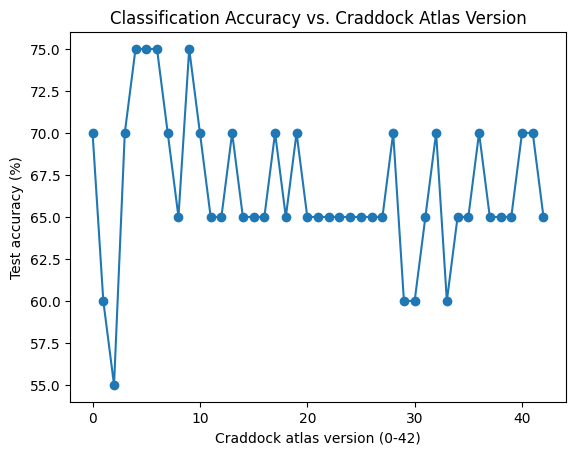

In [22]:
crad_path = 'craddock_2011_parcellations/scorr05_mean_all.nii.gz'
craddock_versions = range(43)

def craddock_atlas(i):
    return index_img(crad_path, i)

accuracies_6 = run_atlas_sweep(craddock_versions, craddock_atlas)

for i, acc in zip(craddock_versions, accuracies_6):
    print(f"version={i}: {acc*100:.2f}%")

plt.plot(list(craddock_versions), [a*100 for a in accuracies_6], marker='o')
plt.xlabel("Craddock atlas version (0-42)")
plt.ylabel("Test accuracy (%)")
plt.title("Classification Accuracy vs. Craddock Atlas Version")
plt.show()

Exercise 7

C:\Users\Asus\AppData\Local\Temp\ipykernel_31240\3507887655.py:12: FutureWarning: boolean values for 'standardize' will be deprecated in nilearn 0.15.0.
Use 'zscore_sample' instead of 'True' or use 'None' instead of 'False'.
  return masker.fit_transform(brain_data.gray_matter_maps)


n_components=1: 60.00%
n_components=2: 65.00%
n_components=3: 60.00%
n_components=4: 55.00%
n_components=5: 60.00%
n_components=6: 60.00%
n_components=7: 55.00%
n_components=8: 60.00%
n_components=9: 60.00%
n_components=10: 60.00%
n_components=11: 60.00%
n_components=12: 75.00%
n_components=13: 75.00%
n_components=14: 75.00%
n_components=15: 75.00%
n_components=16: 75.00%
n_components=17: 75.00%
n_components=18: 70.00%
n_components=19: 70.00%
n_components=20: 70.00%
n_components=21: 70.00%
n_components=22: 75.00%
n_components=23: 75.00%
n_components=24: 75.00%
n_components=25: 75.00%


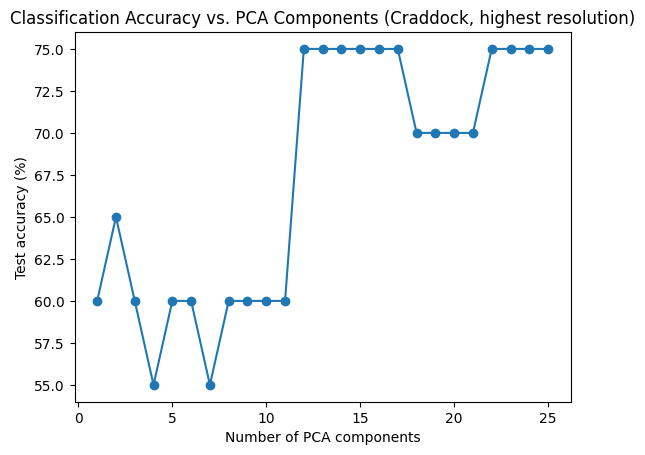

In [23]:
crad_path = 'craddock_2011_parcellations/scorr05_mean_all.nii.gz'
craddock_versions = range(43)

def craddock_atlas(i):
    return index_img(crad_path, i)

def n_regions(i):
    return len(np.unique(craddock_atlas(i).get_fdata())) - 1  # exclude background label 0

best_idx = max(craddock_versions, key=n_regions)
X_best = get_features(craddock_atlas(best_idx))

n_components_list = range(1, 26)
accuracies_7 = run_pca_sweep(X_best, output_variable, n_components_list)

for k, acc in zip(n_components_list, accuracies_7):
    print(f"n_components={k}: {acc*100:.2f}%")

plt.plot(list(n_components_list), [a*100 for a in accuracies_7], marker='o')
plt.xlabel("Number of PCA components")
plt.ylabel("Test accuracy (%)")
plt.title("Classification Accuracy vs. PCA Components (Craddock, highest resolution)")
plt.show()

Exercise 8

C:\Users\Asus\AppData\Local\Temp\ipykernel_31240\3507887655.py:12: FutureWarning: boolean values for 'standardize' will be deprecated in nilearn 0.15.0.
Use 'zscore_sample' instead of 'True' or use 'None' instead of 'False'.
  return masker.fit_transform(brain_data.gray_matter_maps)
c:\Users\Asus\PyCharmMiscProject\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Users\Asus\PyCharmMiscProject\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning

n_clusters=1: 40.00%
n_clusters=2: 55.00%
n_clusters=3: 65.00%
n_clusters=4: 65.00%
n_clusters=5: 65.00%
n_clusters=6: 65.00%
n_clusters=7: 60.00%
n_clusters=8: 70.00%
n_clusters=9: 70.00%
n_clusters=10: 65.00%
n_clusters=11: 65.00%
n_clusters=12: 60.00%
n_clusters=13: 60.00%
n_clusters=14: 55.00%
n_clusters=15: 55.00%
n_clusters=16: 55.00%
n_clusters=17: 65.00%
n_clusters=18: 55.00%
n_clusters=19: 55.00%
n_clusters=20: 65.00%
n_clusters=21: 65.00%
n_clusters=22: 75.00%
n_clusters=23: 60.00%
n_clusters=24: 65.00%
n_clusters=25: 65.00%


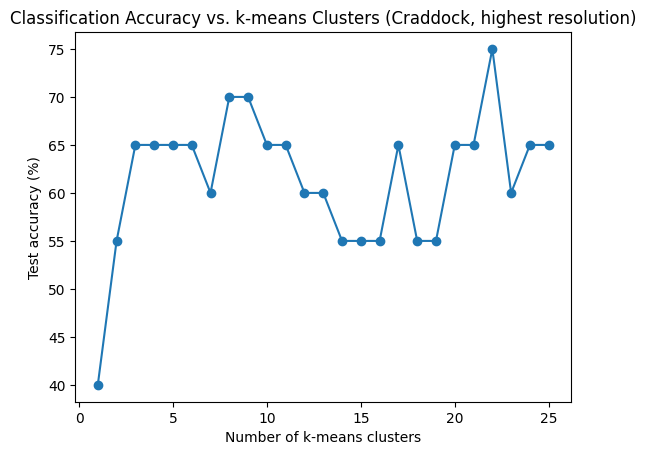

In [24]:
crad_path = 'craddock_2011_parcellations/scorr05_mean_all.nii.gz'
craddock_versions = range(43)

def craddock_atlas(i):
    return index_img(crad_path, i)

def n_regions(i):
    return len(np.unique(craddock_atlas(i).get_fdata())) - 1  # exclude background label 0

best_idx = max(craddock_versions, key=n_regions)
X_best = get_features(craddock_atlas(best_idx))

n_components_list = range(1, 26)
accuracies_8 = run_kmeans_sweep(X_best, output_variable, n_components_list)

for k, acc in zip(n_components_list, accuracies_8):
    print(f"n_clusters={k}: {acc*100:.2f}%")

plt.plot(list(n_components_list), [a*100 for a in accuracies_8], marker='o')
plt.xlabel("Number of k-means clusters")
plt.ylabel("Test accuracy (%)")
plt.title("Classification Accuracy vs. k-means Clusters (Craddock, highest resolution)")
plt.show()

Exercise 9

C:\Users\Asus\AppData\Local\Temp\ipykernel_31240\3507887655.py:12: FutureWarning: boolean values for 'standardize' will be deprecated in nilearn 0.15.0.
Use 'zscore_sample' instead of 'True' or use 'None' instead of 'False'.
  return masker.fit_transform(brain_data.gray_matter_maps)


k=2: 60.00%
k=4: 85.00%
k=6: 85.00%
k=8: 80.00%
k=10: 80.00%


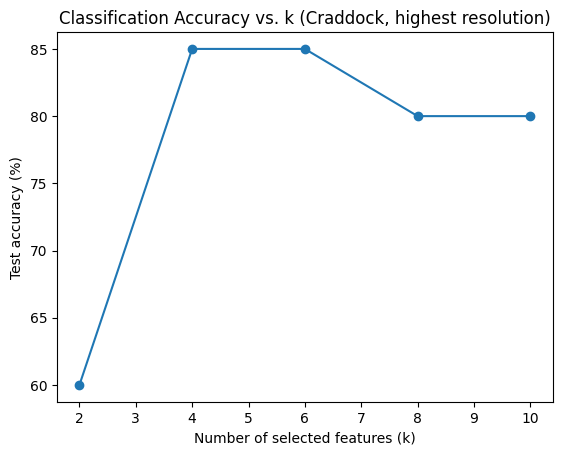

In [25]:
crad_path = 'craddock_2011_parcellations/scorr05_mean_all.nii.gz'
craddock_versions = range(43)

def craddock_atlas(i):
    return index_img(crad_path, i)

def n_regions(i):
    return len(np.unique(craddock_atlas(i).get_fdata())) - 1  # exclude background label 0

best_idx = max(craddock_versions, key=n_regions)
X_best = get_features(craddock_atlas(best_idx))

k_list = [2, 4, 6, 8, 10]
accuracies_9 = run_selectk_sweep(X_best, output_variable, k_list)

for k, acc in zip(k_list, accuracies_9):
    print(f"k={k}: {acc*100:.2f}%")

plt.plot(k_list, [a*100 for a in accuracies_9], marker='o')
plt.xlabel("Number of selected features (k)")
plt.ylabel("Test accuracy (%)")
plt.title("Classification Accuracy vs. k (Craddock, highest resolution)")
plt.show()

Exercise 10

In [26]:
crad_path = 'craddock_2011_parcellations/scorr05_mean_all.nii.gz'
craddock_versions = range(43)

def craddock_atlas(i):
    return index_img(crad_path, i)

stack_acc_10 = run_stacking_sweep(craddock_versions, craddock_atlas)
print(f"Stacking model accuracy: {stack_acc_10*100:.2f}%")

C:\Users\Asus\AppData\Local\Temp\ipykernel_31240\3507887655.py:12: FutureWarning: boolean values for 'standardize' will be deprecated in nilearn 0.15.0.
Use 'zscore_sample' instead of 'True' or use 'None' instead of 'False'.
  return masker.fit_transform(brain_data.gray_matter_maps)
C:\Users\Asus\AppData\Local\Temp\ipykernel_31240\3507887655.py:12: FutureWarning: boolean values for 'standardize' will be deprecated in nilearn 0.15.0.
Use 'zscore_sample' instead of 'True' or use 'None' instead of 'False'.
  return masker.fit_transform(brain_data.gray_matter_maps)
C:\Users\Asus\AppData\Local\Temp\ipykernel_31240\3507887655.py:12: FutureWarning: boolean values for 'standardize' will be deprecated in nilearn 0.15.0.
Use 'zscore_sample' instead of 'True' or use 'None' instead of 'False'.
  return masker.fit_transform(brain_data.gray_matter_maps)
C:\Users\Asus\AppData\Local\Temp\ipykernel_31240\3507887655.py:12: FutureWarning: boolean values for 'standardize' will be deprecated in nilearn 0.1

Stacking model accuracy: 65.00%
